# Spotify Track Clustering

## Dataset
The dataset contains 114,000 rows and 21 columns with song details and audio characteristics.

## Objective
Group similar songs using K-Means and DBSCAN. This is an unsupervised project with no target variable.

## Selected Features
Danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, and tempo.

## Preprocessing
Exclude popularity, track_genre, and the index column. Remove repeated track IDs and scale the audio features.

## Evaluation
Evaluate clusters using silhouette scores, visualize them using PCA, and interpret their audio characteristics.

Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("dataset.csv")

df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Rows: 114000
Columns: 21

Column names:
['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [5]:
df.describe().round(3)

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.00,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000
mean,56999.50,33.239,228029.153,0.567,0.641,5.309,-8.259,0.638,0.085,0.315,0.156,0.214,0.474,122.148,3.904
std,32909.11,22.305,107297.713,0.174,0.252,3.560,5.029,0.481,0.106,0.333,0.310,0.190,0.259,29.978,0.433
min,0.00,0.000,0.000,0.000,0.000,0.000,-49.531,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,28499.75,17.000,174066.000,0.456,0.472,2.000,-10.013,0.000,0.036,0.017,0.000,0.098,0.260,99.219,4.000
50%,56999.50,35.000,212906.000,0.580,0.685,5.000,-7.004,1.000,0.049,0.169,0.000,0.132,0.464,122.017,4.000
75%,85499.25,50.000,261506.000,0.695,0.854,8.000,-5.003,1.000,0.084,0.598,0.049,0.273,0.683,140.071,4.000
max,113999.00,100.000,5237295.000,0.985,1.000,11.000,4.532,1.000,0.965,0.996,1.000,1.000,0.995,243.372,5.000


In [6]:
missing = df.isna().sum()

print(missing[missing > 0])

artists       1
album_name    1
track_name    1
dtype: int64


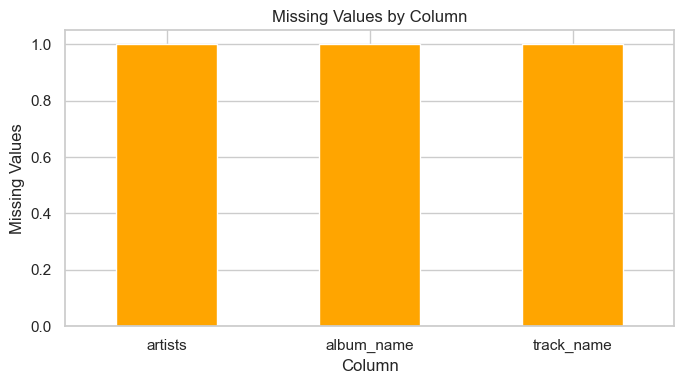

In [7]:
missing[missing > 0].plot(
    kind="bar",
    figsize=(7, 4),
    color="orange"
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Repeated track IDs:",
    df["track_id"].duplicated().sum()
)

print(
    "Unique tracks:",
    df["track_id"].nunique()
)

Exact duplicate rows: 0
Repeated track IDs: 24259
Unique tracks: 89741


In [9]:
eda_df = df.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
).copy()

eda_df = eda_df.drop_duplicates(
    subset="track_id",
    keep="first"
).reset_index(drop=True)

print("Original rows:", len(df))
print("Unique-track rows:", len(eda_df))

Original rows: 114000
Unique-track rows: 89741


In [10]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

eda_df[features].head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917
1,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489
2,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332
3,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740
4,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949


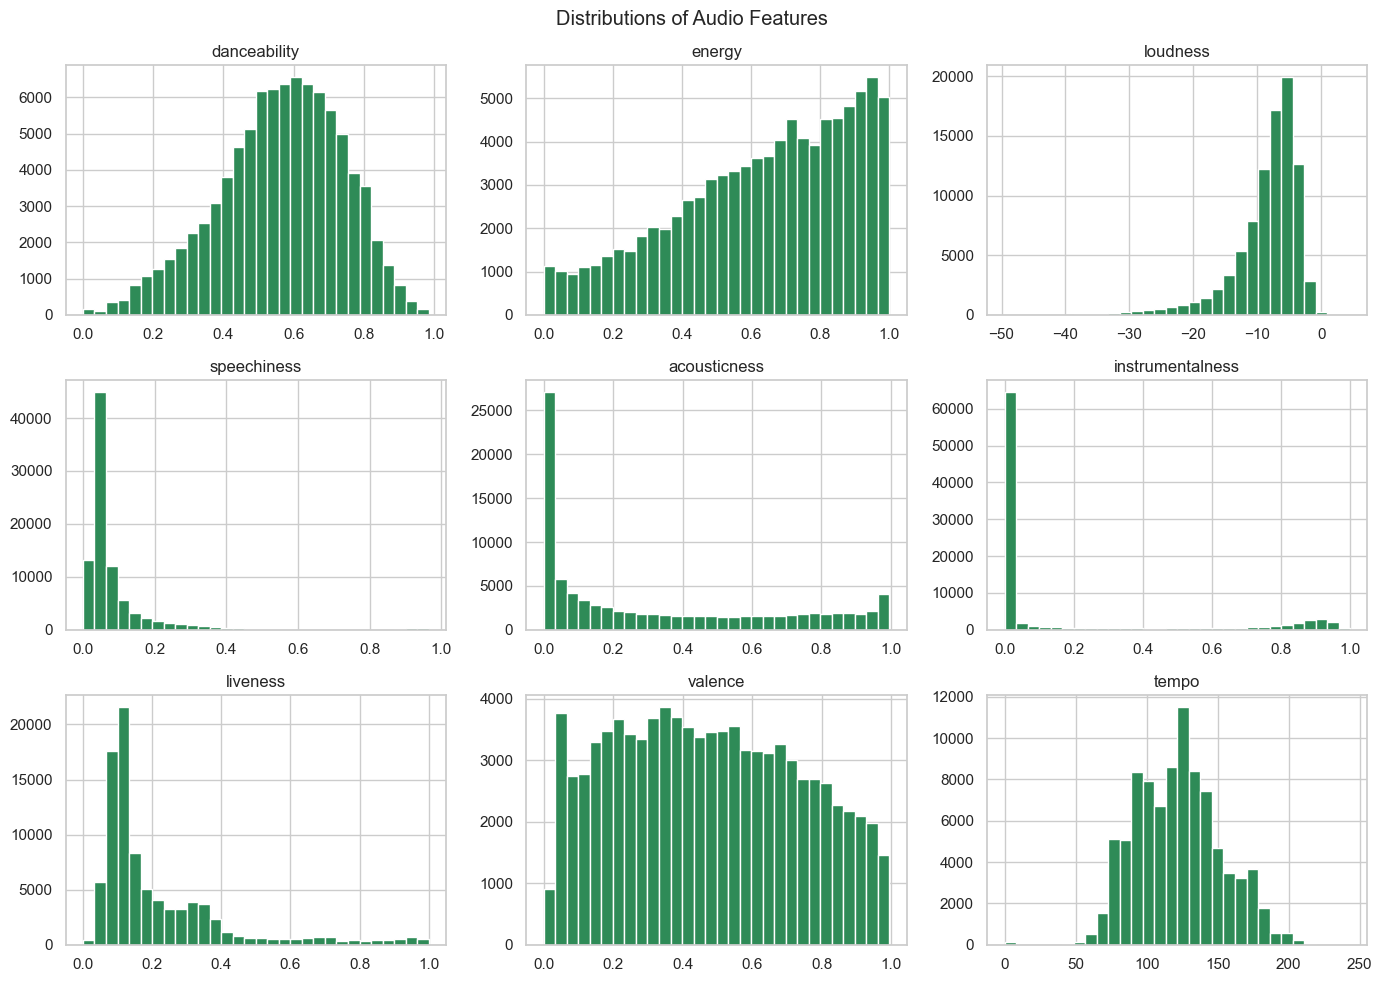

In [42]:
eda_df[features].hist(
    bins=30,
    figsize=(14, 10),
    color="seagreen",
    edgecolor="white"
)

plt.suptitle("Distributions of Audio Features")
plt.tight_layout()
plt.show()

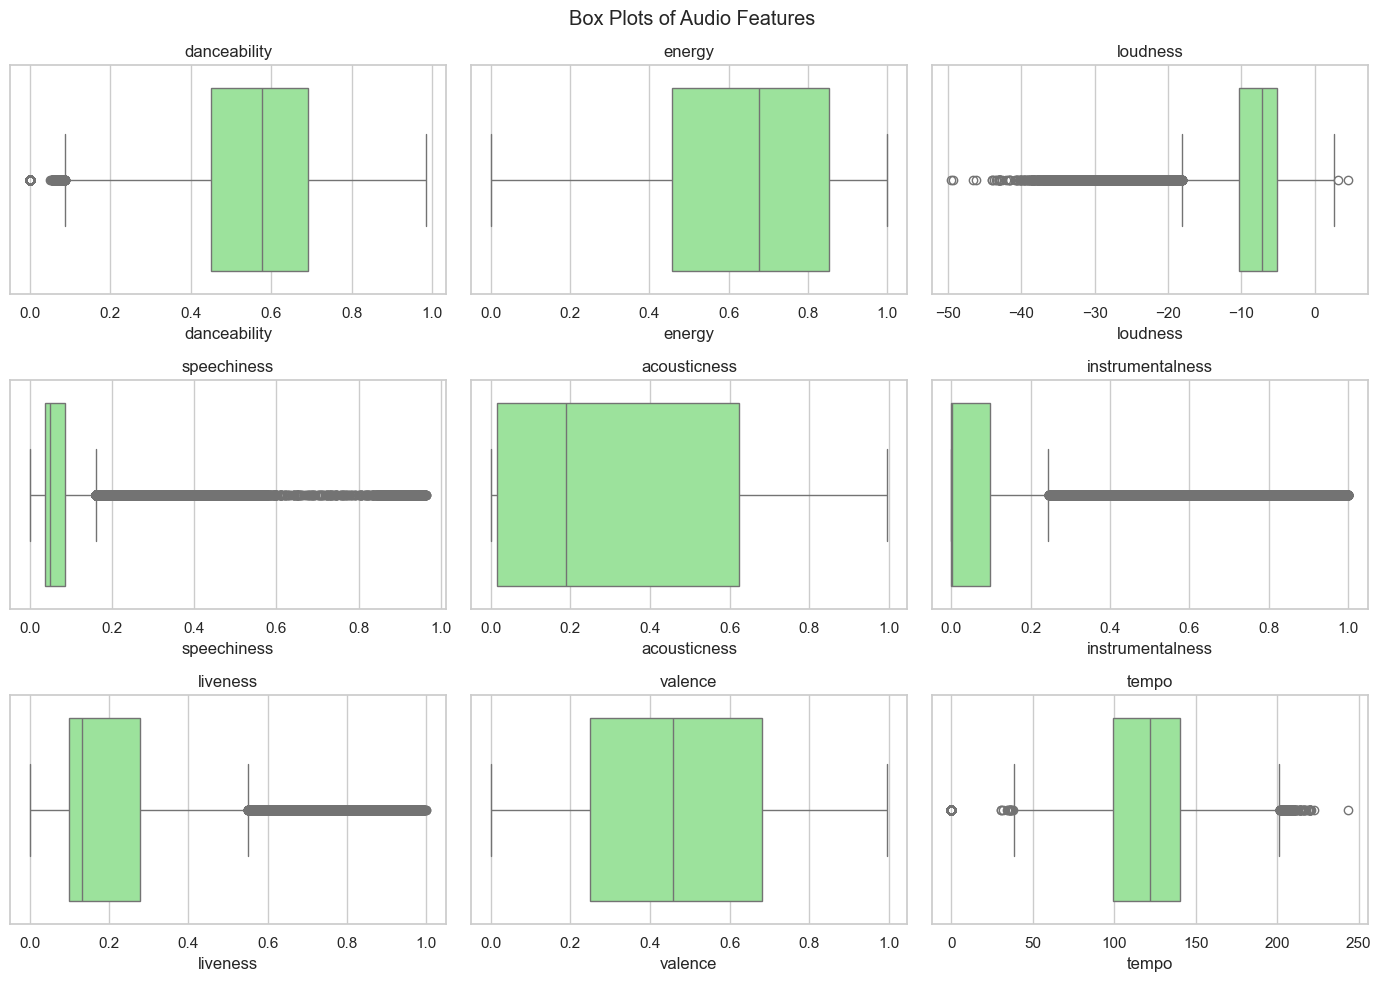

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(
        x=eda_df[feature],
        ax=ax,
        color="lightgreen"
    )
    ax.set_title(feature)

plt.suptitle("Box Plots of Audio Features")
plt.tight_layout()
plt.show()

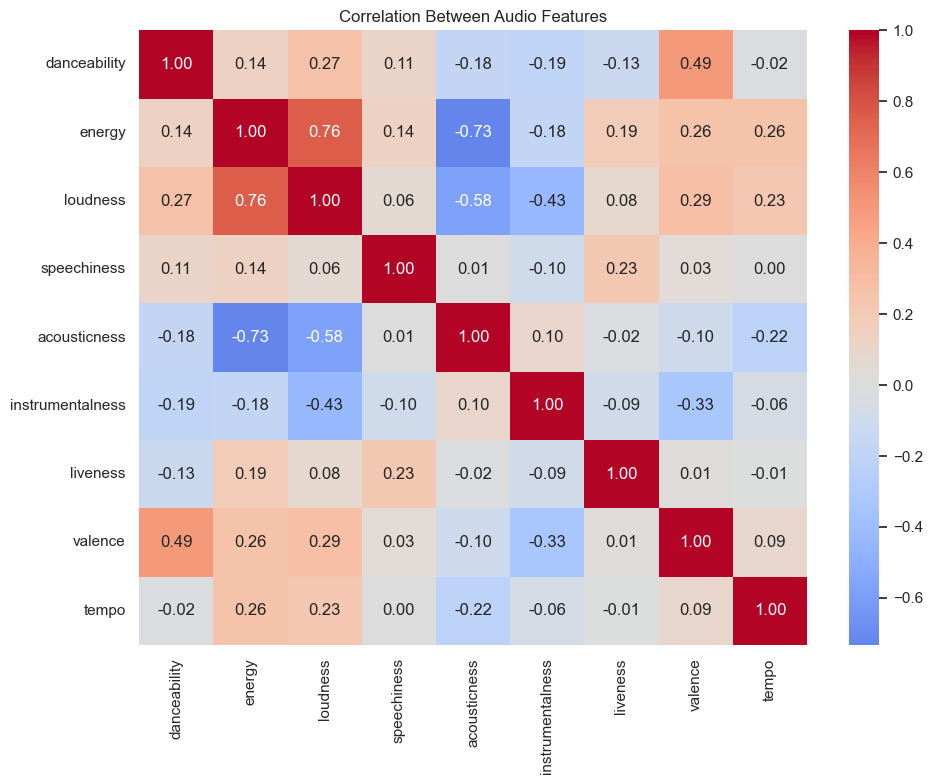

In [13]:
correlation = eda_df[features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Audio Features")
plt.tight_layout()
plt.show()

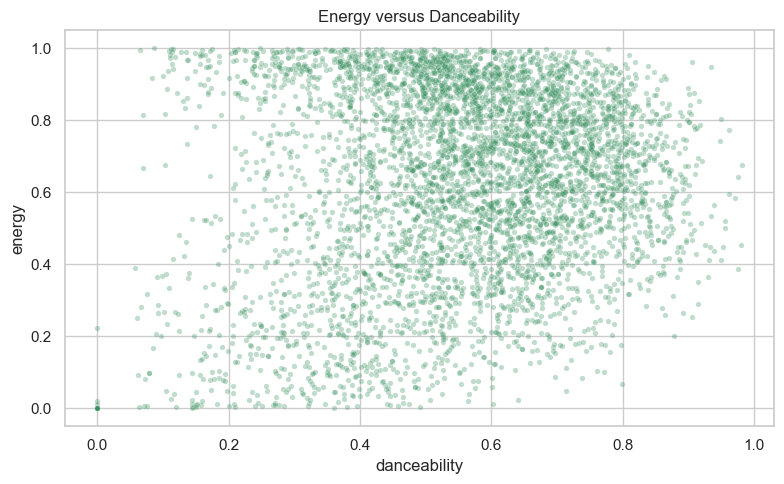

In [14]:
plot_sample = eda_df.sample(
    n=min(5000, len(eda_df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_sample,
    x="danceability",
    y="energy",
    alpha=0.3,
    s=15,
    color="seagreen"
)

plt.title("Energy versus Danceability")
plt.tight_layout()
plt.show()

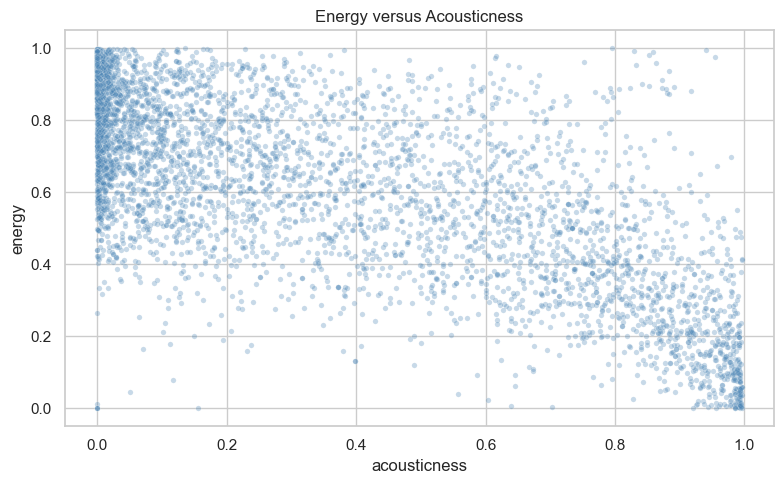

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_sample,
    x="acousticness",
    y="energy",
    alpha=0.3,
    s=15,
    color="steelblue"
)

plt.title("Energy versus Acousticness")
plt.tight_layout()
plt.show()

In [16]:
print(
    eda_df[features]
    .agg(["min", "max"])
    .round(3)
)

print(
    "\nTracks with zero tempo:",
    (eda_df["tempo"] == 0).sum()
)

     danceability  energy  loudness  speechiness  acousticness  \
min         0.000     0.0   -49.531        0.000         0.000   
max         0.985     1.0     4.532        0.965         0.996   

     instrumentalness  liveness  valence    tempo  
min               0.0       0.0    0.000    0.000  
max               1.0       1.0    0.995  243.372  

Tracks with zero tempo: 157


In [17]:
df = df.drop(
    columns=["popularity", "track_genre", "Unnamed: 0"],
    errors="ignore"
)

print(df.columns.tolist())

['track_id', 'artists', 'album_name', 'track_name', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


In [18]:
features = [
    "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo"
]

X = df[features].copy()

X.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917
1,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489
2,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332
3,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740
4,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949


In [19]:
df = df.drop(
    columns=["Unnamed: 0", "popularity", "track_genre"],
    errors="ignore"
).copy()

In [20]:
df = df.drop_duplicates(
    subset="track_id",
    keep="first"
).reset_index(drop=True)

print("Rows after removing repeated tracks:", len(df))

Rows after removing repeated tracks: 89741


In [21]:
text_columns = ["artists", "album_name", "track_name"]

df[text_columns] = df[text_columns].fillna("Unknown")

print(df[text_columns].isna().sum())

artists       0
album_name    0
track_name    0
dtype: int64


In [22]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

X = df[features].copy()

print("Clustering input shape:", X.shape)

Clustering input shape: (89741, 9)


In [23]:
import numpy as np

X = X.replace([np.inf, -np.inf], np.nan)

print("Missing values:")
print(X.isna().sum())

Missing values:
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
dtype: int64


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled = preprocessor.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (89741, 9)


In [25]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

X_scaled_df.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.644260,-0.675976,0.335731,0.490464,-0.875177,-0.535478,0.723666,0.934036,-1.133609
1,-0.804604,-1.825609,-1.673094,-0.098361,1.760797,-0.535464,-0.595072,-0.770280,-1.479854
2,-0.702731,-1.073476,-0.236523,-0.280217,-0.349638,-0.535481,-0.512971,-1.329508,-1.518271
3,-1.676186,-2.240257,-1.918236,-0.451480,1.704637,-0.535263,-0.436002,-1.242010,1.981637
4,0.316001,-0.746123,-0.226373,-0.307584,0.415912,-0.535481,-0.687948,-1.150708,-0.070037


In [26]:
print("Means:")
print(X_scaled_df.mean().round(2))

print("\nStandard deviations:")
print(X_scaled_df.std(ddof=0).round(2))

Means:
danceability       -0.0
energy              0.0
loudness           -0.0
speechiness         0.0
acousticness        0.0
instrumentalness   -0.0
liveness           -0.0
valence             0.0
tempo              -0.0
dtype: float64

Standard deviations:
danceability        1.0
energy              1.0
loudness            1.0
speechiness         1.0
acousticness        1.0
instrumentalness    1.0
liveness            1.0
valence             1.0
tempo               1.0
dtype: float64


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_scaled),
    size=min(10000, len(X_scaled)),
    replace=False
)

X_compare = X_scaled[sample_indices]

print("Comparison sample:", X_compare.shape)

Comparison sample: (10000, 9)


In [29]:
def evaluate_clusters(data, labels):
    assigned = labels != -1
    valid_data = data[assigned]
    valid_labels = labels[assigned]

    n_clusters = len(np.unique(valid_labels))
    noise_percent = (~assigned).mean() * 100

    score = np.nan

    if 2 <= n_clusters < len(valid_data):
        # Limit silhouette evaluation to 2,000 songs.
        if len(valid_data) > 2000:
            sample_rng = np.random.default_rng(42)
            indices = sample_rng.choice(
                len(valid_data), 2000, replace=False
            )
            score_data = valid_data[indices]
            score_labels = valid_labels[indices]
        else:
            score_data = valid_data
            score_labels = valid_labels

        if 2 <= len(np.unique(score_labels)) < len(score_labels):
            score = silhouette_score(score_data, score_labels)

    return n_clusters, score, noise_percent

In [30]:
kmeans_results = []

for k in range(2, 13):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_compare)

    n_clusters, score, noise = evaluate_clusters(
        X_compare, labels
    )

    kmeans_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": score
    })

kmeans_results = pd.DataFrame(kmeans_results)

print(kmeans_results.round(4).to_string(index=False))

 k    inertia  silhouette
 2 71438.4570      0.2531
 3 63280.2643      0.1607
 4 56621.8943      0.1695
 5 50970.5144      0.1778
 6 46231.2436      0.1920
 7 41920.2629      0.2013
 8 39615.1586      0.1836
 9 37602.1741      0.1854
10 36089.8192      0.1691
11 34744.0709      0.1702
12 33666.2400      0.1599


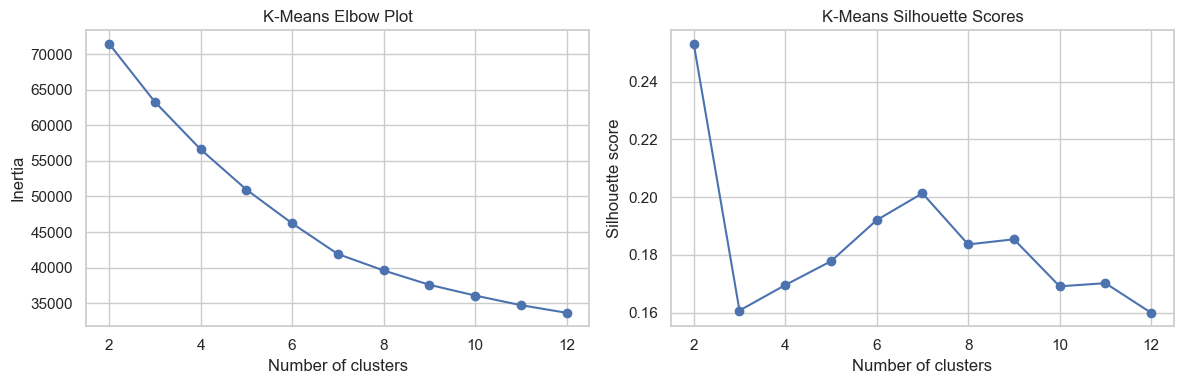

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    kmeans_results["k"],
    kmeans_results["inertia"],
    marker="o"
)
axes[0].set_title("K-Means Elbow Plot")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    kmeans_results["k"],
    kmeans_results["silhouette"],
    marker="o"
)
axes[1].set_title("K-Means Silhouette Scores")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

In [32]:
best_row = kmeans_results.loc[
    kmeans_results["silhouette"].idxmax()
]

best_k = int(best_row["k"])

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_compare)

print("Candidate number of clusters:", best_k)

print("\nCluster sizes:")
print(
    pd.Series(kmeans_labels)
    .value_counts()
    .sort_index()
)

Candidate number of clusters: 2

Cluster sizes:
0    7587
1    2413
Name: count, dtype: int64


In [34]:
dbscan_results = []

for eps in [0.5, 0.8, 1.1, 1.4, 1.7]:
    for min_samples in [5, 15, 30]:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            n_jobs=-1
        )

        labels = model.fit_predict(X_compare)

        n_clusters, score, noise = evaluate_clusters(
            X_compare, labels
        )

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "silhouette": score,
            "noise_percent": noise
        })

dbscan_results = pd.DataFrame(dbscan_results)

print(
    dbscan_results
    .sort_values("silhouette", ascending=False)
    .round(4)
    .to_string(index=False)
)

 eps  min_samples  clusters  silhouette  noise_percent
 1.4           15         2      0.5827           6.75
 1.7           15         2      0.5735           2.30
 1.7           30         2      0.5709           3.16
 1.1           30         2      0.4751          30.85
 1.7            5         5      0.3777           1.43
 1.4            5         4      0.3640           3.78
 1.1           15         3      0.3037          22.15
 0.8           30         7      0.1552          76.34
 0.8           15         7      0.1037          58.61
 0.5            5        65     -0.0031          91.15
 1.1            5        13     -0.1439          12.86
 0.8            5        28     -0.2864          39.50
 0.5           15         0         NaN         100.00
 0.5           30         0         NaN         100.00
 1.4           30         1         NaN          10.71


In [35]:
valid_results = dbscan_results.dropna(
    subset=["silhouette"]
)

dbscan_model = None
dbscan_labels = None

if valid_results.empty:
    print("No evaluable DBSCAN configuration.")
    print("We need to adjust the parameter range.")
else:
    best_dbscan = valid_results.loc[
        valid_results["silhouette"].idxmax()
    ]

    dbscan_model = DBSCAN(
        eps=float(best_dbscan["eps"]),
        min_samples=int(best_dbscan["min_samples"]),
        n_jobs=-1
    )

    dbscan_labels = dbscan_model.fit_predict(X_compare)

    print("Candidate parameters:")
    print(best_dbscan)

    print("\nCluster sizes (-1 means noise):")
    print(
        pd.Series(dbscan_labels)
        .value_counts()
        .sort_index()
    )

Candidate parameters:
eps               1.400000
min_samples      15.000000
clusters          2.000000
silhouette        0.582724
noise_percent     6.750000
Name: 10, dtype: float64

Cluster sizes (-1 means noise):
-1     675
 0    9263
 1      62
Name: count, dtype: int64


In [36]:
comparison = []

algorithms = [("K-Means", kmeans_labels)]

if dbscan_labels is not None:
    algorithms.append(("DBSCAN", dbscan_labels))

for name, labels in algorithms:
    clusters, score, noise = evaluate_clusters(
        X_compare, labels
    )

    comparison.append({
        "Algorithm": name,
        "Clusters": clusters,
        "Silhouette": score,
        "Noise (%)": noise,
        "Assigned (%)": 100 - noise
    })

comparison = pd.DataFrame(comparison)

print(comparison.round(4).to_string(index=False))

Algorithm  Clusters  Silhouette  Noise (%)  Assigned (%)
  K-Means         2      0.2531       0.00        100.00
   DBSCAN         2      0.5827       6.75         93.25


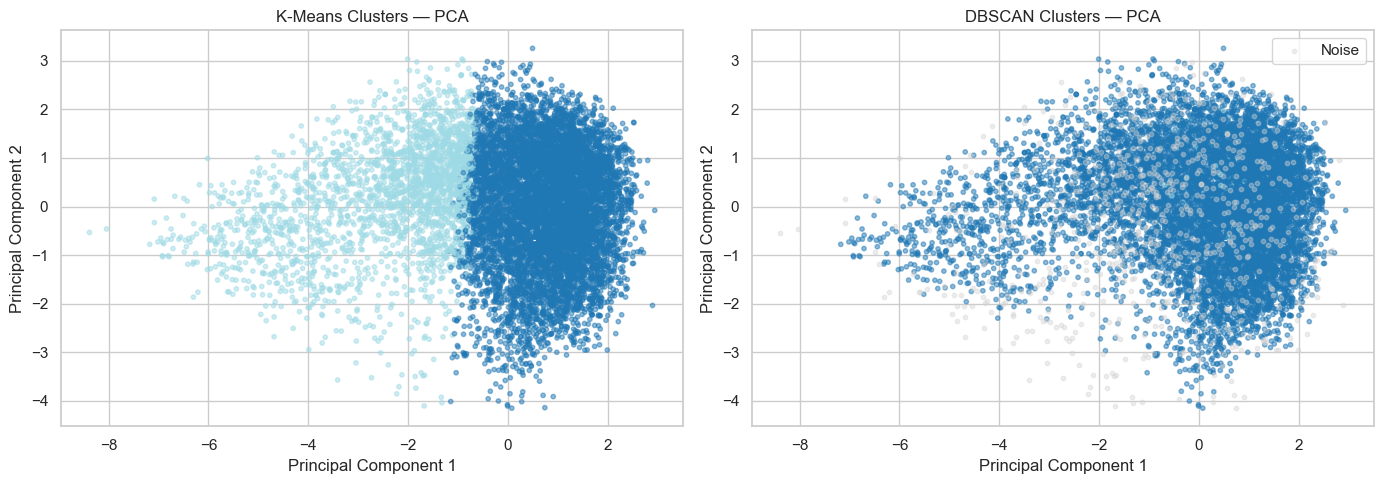

Variance explained by two components: 47.76 %


In [37]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Reduce nine features to two for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_compare)

models = [("K-Means", kmeans_labels)]

if dbscan_labels is not None:
    models.append(("DBSCAN", dbscan_labels))

fig, axes = plt.subplots(
    1, len(models),
    figsize=(7 * len(models), 5),
    squeeze=False
)

for ax, (name, labels) in zip(axes[0], models):
    labels = np.asarray(labels)
    assigned = labels != -1

    ax.scatter(
        X_pca[assigned, 0],
        X_pca[assigned, 1],
        c=labels[assigned],
        cmap="tab20",
        s=10,
        alpha=0.5
    )

    if (~assigned).any():
        ax.scatter(
            X_pca[~assigned, 0],
            X_pca[~assigned, 1],
            color="lightgray",
            s=10,
            alpha=0.4,
            label="Noise"
        )
        ax.legend()

    ax.set_title(f"{name} Clusters — PCA")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [38]:
print("DBSCAN cluster sizes (-1 = noise):")
print(pd.Series(dbscan_labels).value_counts().sort_index())

profile = X.iloc[sample_indices].copy()
profile["cluster"] = dbscan_labels

display(
    profile[profile["cluster"] != -1]
    .groupby("cluster")[features]
    .mean()
    .round(3)
)

DBSCAN cluster sizes (-1 = noise):
-1     675
 0    9263
 1      62
Name: count, dtype: int64


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.568,0.64,-8.251,0.074,0.311,0.159,0.197,0.476,122.309
1,0.546,0.77,-10.315,0.925,0.819,0.000,0.771,0.374,91.992


In [39]:
print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

profile = X.iloc[sample_indices].copy()
profile["cluster"] = kmeans_labels

display(
    profile.groupby("cluster")[features]
    .mean()
    .round(3)
)

K-Means cluster sizes:
0    7587
1    2413
Name: count, dtype: int64


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.595,0.744,-6.585,0.098,0.190,0.124,0.228,0.521,126.557
1,0.457,0.290,-14.783,0.059,0.752,0.329,0.181,0.309,107.912


In [40]:
from sklearn.cluster import KMeans

final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["cluster"] = final_kmeans.fit_predict(X_scaled)

print("Full-dataset cluster sizes:")
print(df["cluster"].value_counts().sort_index())

display(
    df.groupby("cluster")[features]
    .mean()
    .round(3)
)

Full-dataset cluster sizes:
cluster
0    22281
1    67460
Name: count, dtype: int64


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.459,0.296,-14.589,0.059,0.750,0.329,0.182,0.305,109.300
1,0.596,0.746,-6.487,0.097,0.189,0.122,0.229,0.524,126.272


In [43]:
cluster_names = {
    0: "Acoustic and Low Energy",
    1: "Energetic and Danceable"
}

df["cluster_name"] = df["cluster"].map(cluster_names)

display(
    df[
        ["track_name", "artists", "cluster", "cluster_name"]
    ].head(10)
)

,track_name,artists,cluster,cluster_name
0,Comedy,Gen Hoshino,1,Energetic and Danceable
1,Ghost - Acoustic,Ben Woodward,0,Acoustic and Low Energy
2,To Begin Again,Ingrid Michaelson;ZAYN,0,Acoustic and Low Energy
3,Can't Help Falling In Love,Kina Grannis,0,Acoustic and Low Energy
4,Hold On,Chord Overstreet,0,Acoustic and Low Energy
5,Days I Will Remember,Tyrone Wells,1,Energetic and Danceable
6,Say Something,A Great Big World;Christina Aguilera,0,Acoustic and Low Energy
7,I'm Yours,Jason Mraz,1,Energetic and Danceable
8,Lucky,Jason Mraz;Colbie Caillat,1,Energetic and Danceable
9,Hunger,Ross Copperman,1,Energetic and Danceable


In [44]:
from sklearn.metrics import silhouette_score

final_score = silhouette_score(
    X_scaled,
    df["cluster"].to_numpy(),
    sample_size=2000,
    random_state=42
)

print("Final K-Means clusters:", final_kmeans.n_clusters)
print("Sampled silhouette score:", round(final_score, 4))

print("\nCluster sizes:")
print(df["cluster_name"].value_counts())

Final K-Means clusters: 2
Sampled silhouette score: 0.2594

Cluster sizes:
cluster_name
Energetic and Danceable    67460
Acoustic and Low Energy    22281
Name: count, dtype: int64


In [45]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("kmeans", final_kmeans)
])

In [46]:
import numpy as np

test_songs = df[features].head(10)

pipeline_predictions = final_pipeline.predict(test_songs)
existing_predictions = df["cluster"].head(10).to_numpy()

assert np.array_equal(
    pipeline_predictions,
    existing_predictions
), "Predictions differ. Check the preprocessing and final model."

print("Verification passed: pipeline predictions match.")

Verification passed: pipeline predictions match.


In [47]:
import joblib
from pathlib import Path

output_folder = Path.cwd()

model_bundle = {
    "pipeline": final_pipeline,
    "features": features,
    "cluster_names": cluster_names,
    "sampled_silhouette_score": float(final_score)
}

model_path = output_folder / "spotify_clustering.joblib"
songs_path = output_folder / "spotify_clustered.csv"

joblib.dump(model_bundle, model_path)

df.to_csv(songs_path, index=False)

print("Model saved:", model_path)
print("Songs saved:", songs_path)

Model saved: C:\Users\R Prithesa\Documents\Spotify rename dataset\spotify_clustering.joblib
Songs saved: C:\Users\R Prithesa\Documents\Spotify rename dataset\spotify_clustered.csv


In [48]:
import joblib
import numpy as np

saved_bundle = joblib.load("spotify_clustering.joblib")

predictions = saved_bundle["pipeline"].predict(
    df[saved_bundle["features"]].head(10)
)

assert np.array_equal(
    predictions,
    df["cluster"].head(10).to_numpy()
)

print("Saved model loaded successfully. Predictions match.")

Saved model loaded successfully. Predictions match.


In [49]:
import sklearn
import pandas as pd
import numpy as np
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.7.2
pandas: 2.3.3
numpy: 2.3.5
joblib: 1.5.2


In [50]:
%%writefile app.py
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Spotify Track Clustering",
    page_icon="🎵",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent


@st.cache_resource
def load_model():
    return joblib.load(BASE_DIR / "spotify_clustering.joblib")


@st.cache_data
def load_songs():
    return pd.read_csv(BASE_DIR / "spotify_clustered.csv")


bundle = load_model()
songs = load_songs()

pipeline = bundle["pipeline"]
features = bundle["features"]
cluster_names = bundle["cluster_names"]

st.title("🎵 Spotify Track Clustering")
st.write(
    "Explore songs grouped by their audio characteristics, "
    "or enter audio features to find a cluster."
)

st.caption(
    "K-Means with 2 clusters | "
    f"Sampled silhouette score: "
    f"{bundle['sampled_silhouette_score']:.4f}"
)

st.info(
    "These are broad audio groups with some overlap. "
    "The app groups songs; it does not predict popularity or genre."
)

explore_tab, predict_tab = st.tabs([
    "Explore Songs",
    "Find a Cluster"
])

with explore_tab:
    selected_cluster = st.selectbox(
        "Choose a song group",
        options=sorted(cluster_names),
        format_func=lambda value: cluster_names[value]
    )

    group = songs[
        songs["cluster"] == selected_cluster
    ].copy()

    st.metric("Songs in this group", f"{len(group):,}")

    search = st.text_input("Search by song or artist")

    if search.strip():
        query = search.strip()

        matches = (
            group["track_name"].fillna("").str.contains(
                query, case=False, regex=False
            )
            | group["artists"].fillna("").str.contains(
                query, case=False, regex=False
            )
        )

        group = group[matches]

    st.write(f"Matching songs: {len(group):,}")

    st.dataframe(
        group[
            ["track_name", "artists", "cluster_name"]
        ].head(100),
        hide_index=True,
        use_container_width=True
    )

    st.caption("Showing up to 100 matching songs.")

with predict_tab:
    st.write(
        "Enter original audio feature values. "
        "The saved pipeline handles scaling automatically."
    )

    with st.form("audio_features"):
        left, right = st.columns(2)

        with left:
            danceability = st.slider(
                "Danceability", 0.0, 1.0, 0.5, 0.01
            )
            energy = st.slider(
                "Energy", 0.0, 1.0, 0.5, 0.01
            )
            loudness = st.slider(
                "Loudness (dB)", -60.0, 5.0, -8.0, 0.1
            )
            speechiness = st.slider(
                "Speechiness", 0.0, 1.0, 0.05, 0.01
            )
            acousticness = st.slider(
                "Acousticness", 0.0, 1.0, 0.3, 0.01
            )

        with right:
            instrumentalness = st.slider(
                "Instrumentalness", 0.0, 1.0, 0.0, 0.01
            )
            liveness = st.slider(
                "Liveness", 0.0, 1.0, 0.2, 0.01
            )
            valence = st.slider(
                "Valence", 0.0, 1.0, 0.5, 0.01
            )
            tempo = st.slider(
                "Tempo (BPM)", 0.0, 250.0, 120.0, 1.0
            )

        submitted = st.form_submit_button("Find Cluster")

    if submitted:
        values = {
            "danceability": danceability,
            "energy": energy,
            "loudness": loudness,
            "speechiness": speechiness,
            "acousticness": acousticness,
            "instrumentalness": instrumentalness,
            "liveness": liveness,
            "valence": valence,
            "tempo": tempo
        }

        input_data = pd.DataFrame(
            [values], columns=features
        )

        cluster = int(pipeline.predict(input_data)[0])

        st.success(f"Song group: {cluster_names[cluster]}")

        examples = songs[
            songs["cluster"] == cluster
        ]

        st.write("Example songs from this group")

        st.dataframe(
            examples[
                ["track_name", "artists"]
            ].sample(
                n=min(10, len(examples)),
                random_state=42
            ),
            hide_index=True,
            use_container_width=True
        )

        st.caption(
            "Examples share the predicted cluster; "
            "they are not ranked by similarity."
        )

Writing app.py


In [51]:
%%writefile requirements.txt
streamlit
scikit-learn==1.7.2
pandas==2.3.3
numpy==2.3.5
joblib==1.5.2

Writing requirements.txt


## Results and Conclusion

K-Means was evaluated with 2–12 clusters. Two clusters achieved
the highest sampled silhouette score among the tested values.

On the 10,000-song comparison sample:
- K-Means silhouette: 0.2531, with all songs assigned.
- DBSCAN silhouette: 0.5827 on non-noise songs, with 6.75% noise.
- DBSCAN produced one large cluster of 9,263 songs and a small
  cluster of 62 songs.

K-Means was selected for the application because its groups were
more useful for organizing all songs and it supports new inputs.

The final model was fitted on 89,741 unique tracks:
- Acoustic and Low Energy: 22,281 tracks.
- Energetic and Danceable: 67,460 tracks.

The final sampled silhouette score was 0.2594, indicating overlap
between these broad groups.

PCA was used only for visualization. Its two components represented
47.76% of the variance in the comparison sample.

In [53]:
joblib.dump(
    {
        "model": dbscan_model,
        "preprocessor": preprocessor,
        "features": features,
        "sample_indices": sample_indices
    },
    "spotify_dbscan.joblib"
)

comparison.to_csv("model_comparison.csv", index=False)

print("DBSCAN model and comparison results saved.")

DBSCAN model and comparison results saved.


In [54]:
%%writefile README.md
# Spotify Track Clustering

## Objective
Group Spotify songs by audio characteristics using unsupervised learning.

## Dataset
Source: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

The original dataset contains 114,000 rows and 21 columns.
Removing repeated track IDs leaves 89,741 unique tracks.

## Features
Danceability, energy, loudness, speechiness, acousticness,
instrumentalness, liveness, valence, and tempo.

No target variable is used. Popularity and track_genre are excluded
from clustering.

## Workflow
1. Explore missing values, duplicates, distributions, and correlations.
2. Remove repeated track IDs and fill missing song details.
3. Apply median imputation and StandardScaler to numeric features.
4. Compare K-Means and DBSCAN on a reproducible 10,000-song sample.
5. Test K-Means with 2–12 clusters.
6. Evaluate silhouette scores, cluster sizes, and DBSCAN noise.
7. Visualize clusters using PCA and interpret feature averages.
8. Fit the selected K-Means model on all unique tracks.
9. Save the preprocessing pipeline and models.
10. Build a Streamlit application.

## Model Comparison
| Algorithm | Clusters | Sampled silhouette | Noise |
|-----------|----------|--------------------|-------|
| K-Means | 2 | 0.2531 | 0% |
| DBSCAN | 2 | 0.5827 | 6.75% |

DBSCAN silhouette excludes noise points, so the scores cover
different subsets of songs.

DBSCAN produced one large cluster of 9,263 songs and one small
cluster of 62 songs. K-Means was selected because its groups were
more useful for organizing all songs and it supports new inputs.

## Final Results
Final K-Means sampled silhouette score: 0.2594.

- Acoustic and Low Energy: 22,281 songs.
- Energetic and Danceable: 67,460 songs.

The groups overlap and represent broad audio characteristics.
Silhouette score is not prediction accuracy.

## Application
- Browse songs by cluster.
- Search by song name or artist.
- Enter nine audio features to find a cluster.
- View example songs from that cluster.

Examples are not ranked recommendations.

## Run Locally
Install dependencies:
`python -m pip install -r requirements.txt`

Start the app:
`python -m streamlit run app.py`

Keep spotify_clustering.joblib and spotify_clustered.csv
in the same folder as app.py.

## Notebook
Open spotify.ipynb with dataset.csv in the same folder.
The notebook also requires matplotlib, seaborn, and Jupyter.

## Deployment
Public application URL: To be added after deployment.

Writing README.md
